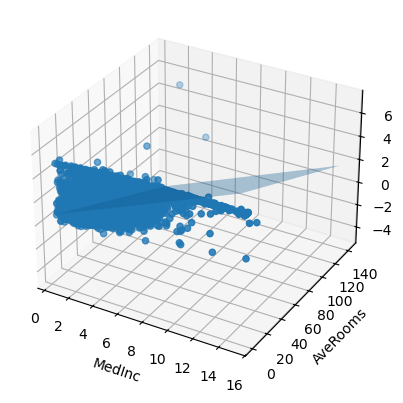


--- PREDICCIONES DE PRECIO DE VIVIENDA ---
Casa 1: Ingreso 5.0 | Cuartos 6.0 -> Precio estimado: $2.5371 (en cientos de miles)
Casa 2: Ingreso 2.5 | Cuartos 4.0 -> Precio estimado: $1.5279 (en cientos de miles)
Casa 3: Ingreso 8.0 | Cuartos 7.0 -> Precio estimado: $3.8015 (en cientos de miles)
Casa 4: Ingreso 1.5 | Cuartos 3.5 -> Precio estimado: $1.1128 (en cientos de miles)
Casa 5: Ingreso 10.0 | Cuartos 5.0 -> Precio estimado: $4.7460 (en cientos de miles)


C:\Users\nehem\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [3]:
# Librerías
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from mpl_toolkits.mplot3d import Axes3D

# Dataset
data = fetch_california_housing(as_frame=True)
df = data.frame

# Variables
X = df[['MedInc','AveRooms']]
y = df['MedHouseVal']

# Modelo
modelo = LinearRegression()
modelo.fit(X,y)

# Crear figura 3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Puntos reales
ax.scatter(df['MedInc'], df['AveRooms'], y)

# Crear plano de regresión
x_surf, y_surf = np.meshgrid(
    np.linspace(df['MedInc'].min(), df['MedInc'].max(), 100),
    np.linspace(df['AveRooms'].min(), df['AveRooms'].max(), 100)
)

z_surf = modelo.intercept_ + modelo.coef_[0]*x_surf + modelo.coef_[1]*y_surf

# Plano
ax.plot_surface(x_surf, y_surf, z_surf, alpha=0.4)

# Etiquetas
ax.set_xlabel("MedInc")
ax.set_ylabel("AveRooms")
ax.set_zlabel("MedHouseVal")

plt.show()



# 1. Definimos 5 casos manuales (Ingreso medio, Promedio de cuartos)
# Ejemplo: Un ingreso de 5.0 y 6 habitaciones promedio
datos_nuevos = np.array([
    [5.0, 6.0],
    [2.5, 4.0],
    [8.0, 7.0],
    [1.5, 3.5],
    [10.0, 5.0]
])

# 2. Realizamos la predicción
predicciones_precios = modelo.predict(datos_nuevos)

# 3. Imprimimos los resultados
print("\n--- PREDICCIONES DE PRECIO DE VIVIENDA ---")
for i, precio in enumerate(predicciones_precios):
    print(f"Casa {i+1}: Ingreso {datos_nuevos[i][0]} | Cuartos {datos_nuevos[i][1]} -> Precio estimado: ${precio:.4f} (en cientos de miles)")